## PageRank y HITS: PageRank

- Google matrix con teletransporte (pesos y nodos colgantes)

- Rankings de entidades y proveedores

- Sensibilidad al factor de amortiguamiento d

### Constantes

- `RANGO_D`: factores de amortiguamiento que se comparan

- `GF_ITER`: iteraciones fijas de GraphFrames

- `N_WEB`: actores por tipo y por d que se exportan para reporte

In [1]:
RANGO_D = [0.50, 0.65, 0.75, 0.85, 0.90, 0.95, 0.99]
GF_ITER = 30
N_WEB = 200

### Detalle

- **Paseo aleatorio:** en cada paso, con probabilidad **d** se sigue una arista del nodo actual

- Con 1 − d se salta a cualquier nodo al azar (**teletransporte**)

- **d = 0.85** (`DAMPING`): valor clásico

### Utilidades

In [2]:
NOTEBOOK = "b_pagerank"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark, hay_gf = crear_spark_grafos(NOTEBOOK)
spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
spark.conf.set("spark.sql.broadcastTimeout", "1200")
verificar_cluster(spark)
print(f"GraphFrames: {'sí' if hay_gf else 'no'}")

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040
GraphFrames: sí


### Carga

In [4]:
config = leer_config()
n_e, n_p = config["n_e"], config["n_p"]
v = pd.read_parquet(datos_dir / "nodos.parquet")
a = pd.read_parquet(datos_dir / "aristas.parquet")
M = matriz_grafo(matriz_bip(a, n_e, n_p, PESO), dirigido=False)
PART = int(spark.conf.get("spark.sql.shuffle.partitions"))
print(f"{n_e:,} entidades + {n_p:,} proveedores | {M.nnz:,} entradas (ambos sentidos) | peso = {PESO}")

2,992 entidades + 86,017 proveedores | 272,198 entradas (ambos sentidos) | peso = n_adj


---
### **1. Google matrix**

A = β · M + (1 − β) · [1/N]ₙₓₙ  ,  r = A · r

- **M**: matriz de transición, Mᵢⱼ = wⱼᵢ / Σₖ wⱼₖ con w = `n_adj`

- **[1/N]ₙₓₙ**: teletransporte; hace al grafo irreducible

- **β** (= `DAMPING` = 0.85): probabilidad de seguir una arista

- **A no se construye**: en cada iteración r = β · M·r + (1 − β)/N

#### a. Spark

- Laristas de M (`P`) se reparten por `src`; el vector de rangos también se reparte por `src`

- El join M ⋈ r queda **co-particionado** y solo se baraja la suma de contribuciones por destino

In [5]:
def pagerank_spark(nodos, aristas, d=DAMPING, tol=TOL_SPARK, max_iter=200):
    n = nodos.count()
    salida = aristas.groupBy("src").agg(F.sum("w").alias("s"))
    P = (aristas.join(salida, "src").select("src", "dst", (F.col("w") / F.col("s")).alias("p"))
                .repartition(PART, "src").cache())
    todos = nodos.select(F.col("idx").alias("src")).repartition(PART, "src").cache()
    colgantes = todos.join(salida, "src", "left_anti").cache()
    hay_colg = colgantes.count() > 0
    rank = todos.withColumn("r", F.lit(1.0 / n)).localCheckpoint()
    for k in range(1, max_iter + 1):
        masa = (rank.join(colgantes, "src").agg(F.sum("r")).first()[0] or 0.0) if hay_colg else 0.0
        contrib = P.join(rank, "src").groupBy(F.col("dst").alias("src")).agg(F.sum(F.col("p") * F.col("r")).alias("c"))
        nuevo = (todos.join(contrib, "src", "left").fillna(0.0, ["c"])
                      .select("src", (F.lit((1 - d) / n) + d * (F.col("c") + F.lit(masa / n))).alias("r"))
                      .repartition(PART, "src").localCheckpoint())
        err = nuevo.join(rank.withColumnRenamed("r", "r0"), "src").agg(F.sum(F.abs(F.col("r") - F.col("r0")))).first()[0]
        if k % 10 == 0:
            print(f"iteración {k}: err = {err:.2e}", flush=True)
        rank = nuevo
        if err < tol:
            break
    return rank.withColumnRenamed("src", "idx"), P, k, err

In [6]:
ar = pd.DataFrame({"src": a.i.to_numpy(), "dst": a.j.to_numpy() + n_e, "w": pesos(a, PESO)})
ar = pd.concat([ar, ar.rename(columns={"src": "dst", "dst": "src"})], ignore_index=True)
nodos_s = spark.createDataFrame(v[["idx"]]).cache()
aristas_s = spark.createDataFrame(ar).cache()
print(f"Spark: {nodos_s.count():,} nodos | {aristas_s.count():,} aristas dirigidas (ambos sentidos)")

Spark: 89,009 nodos | 272,198 aristas dirigidas (ambos sentidos)


In [7]:
t0 = time.time()
rank_s, P_s, k_s, err_s = pagerank_spark(nodos_s, aristas_s)
seg_s = time.time() - t0
r_spark = rank_s.toPandas().sort_values("idx").r.to_numpy()
r_spark = r_spark / r_spark.sum()

t0 = time.time()
r_loc, k_loc, err_loc = pagerank_local(M)
seg_loc = time.time() - t0
print(f"Spark: {k_s} iteraciones en {seg_s:,.0f} s | local: {k_loc} iteraciones en {seg_loc:.2f} s")
print(f"máx |Spark − local| = {np.abs(r_spark - r_loc).max():.2e} | Spearman = {spearman(r_spark, r_loc):.6f}")

iteración 10: err = 3.67e-01


iteración 20: err = 7.23e-02


iteración 30: err = 1.42e-02


iteración 40: err = 2.80e-03


iteración 50: err = 5.52e-04


iteración 60: err = 1.09e-04


iteración 70: err = 2.14e-05


Spark: 75 iteraciones en 56 s | local: 146 iteraciones en 0.12 s
máx |Spark − local| = 5.36e-08 | Spearman = 1.000000


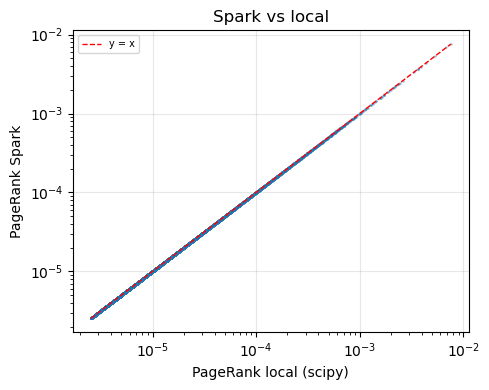

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.loglog(r_loc, r_spark, ".", ms=2, alpha=.3)
lim = [r_loc.min(), r_loc.max()]
ax.plot(lim, lim, "r--", lw=1, label="y = x")
ax.set(xlabel="PageRank local (scipy)", ylabel="PageRank Spark", title="Spark vs local"); ax.legend(fontsize=7)
mostrar_fig("spark_vs_local")

In [9]:
P_s.join(rank_s.withColumnRenamed("idx", "src"), "src").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [src#7L, dst#8L, p#187, r#11219]
   +- SortMergeJoin [src#7L], [src#329L], Inner
      :- Filter isnotnull(src#7L)
      :  +- InMemoryTableScan [src#7L, dst#8L, p#187], [isnotnull(src#7L)]
      :        +- InMemoryRelation [src#7L, dst#8L, p#187], StorageLevel(disk, memory, deserialized, 1 replicas)
      :              +- *(5) Project [src#7L, dst#8L, (w#9 / s#177) AS p#187]
      :                 +- *(5) SortMergeJoin [src#7L], [src#180L], Inner
      :                    :- *(2) Sort [src#7L ASC NULLS FIRST], false, 0
      :                    :  +- Exchange hashpartitioning(src#7L, 24), ENSURE_REQUIREMENTS, [plan_id=36075]
      :                    :     +- *(1) Filter isnotnull(src#7L)
      :                    :        +- InMemoryTableScan [src#7L, dst#8L, w#9], [isnotnull(src#7L)]
      :                    :              +- InMemoryRelation [src#7L, dst#8L, w#9], StorageLevel(disk, memory, deserialized, 1 

- **Spark = local:** diferencia máxima 5.4e-08, Spearman = 1

- **Costo:** 56 s en Spark vs 0.12 s local; en Spark casi todo es costo fijo de coordinar el cluster en cada iteración

- **Overhead:** cada iteración lanza 2 jobs y 24 tareas con muy pocos datos, más un shuffle y un checkpoint (0.75 s por vuelta)

- **Spark conviene** solo si el grafo no cabe en una máquina

#### b. GraphFrames

- `GraphFrame.pageRank` (GraphX) **no admite pesos** y no normaliza a 1

- Se compara solo el **orden** contra la versión local binaria

In [10]:
tiempos = [{"metodo": "propia (Google matrix)", "corre_en": "Spark", "peso": PESO, "iteraciones": k_s,
            "seg": round(seg_s, 1), "spearman_vs_local": spearman(r_spark, r_loc)},
           {"metodo": "propia (Google matrix)", "corre_en": "local (scipy)", "peso": PESO, "iteraciones": k_loc,
            "seg": round(seg_loc, 2), "spearman_vs_local": 1.0}]
if hay_gf:
    from graphframes import GraphFrame
    gf = GraphFrame(nodos_s.withColumnRenamed("idx", "id"), aristas_s.select("src", "dst"))
    t0 = time.time()
    r_gf = gf.pageRank(resetProbability=1 - DAMPING, maxIter=GF_ITER).vertices.toPandas().sort_values("id").pagerank.to_numpy()
    seg_gf = time.time() - t0
    r_bin = pagerank_local(matriz_grafo(matriz_bip(a, n_e, n_p, "binario"), False))[0]
    tiempos.append({"metodo": "GraphFrames pageRank", "corre_en": "Spark", "peso": "binario", "iteraciones": GF_ITER,
                    "seg": round(seg_gf, 1), "spearman_vs_local": spearman(r_gf, r_bin)})
tiempos = pd.DataFrame(tiempos)
tiempos

,metodo,corre_en,peso,iteraciones,seg,spearman_vs_local
0,propia (Google matrix),Spark,n_adj,75,55.80,1.000000
1,propia (Google matrix),local (scipy),n_adj,146,0.12,1.000000
2,GraphFrames pageRank,Spark,binario,30,7.60,0.999994


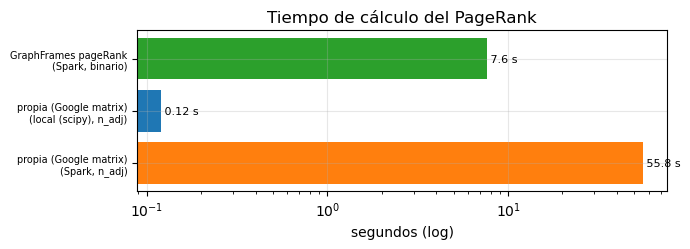

In [11]:
fig, ax = plt.subplots(figsize=(7, 2.6))
etq = [f"{m}\n({c}, {p})" for m, c, p in zip(tiempos.metodo, tiempos.corre_en, tiempos.peso)]
ax.barh(etq, tiempos.seg, color=["tab:orange", "tab:blue", "tab:green"][:len(tiempos)])
for j, s_ in enumerate(tiempos.seg):
    ax.text(s_, j, f" {s_:g} s", va="center", fontsize=8)
ax.set(xscale="log", xlabel="segundos (log)", title="Tiempo de cálculo del PageRank"); ax.tick_params(axis="y", labelsize=7)
mostrar_fig("tiempos")

- **GraphFrames** reproduce el orden de la versión binaria (Spearman 0.99999) en 8 s

- **No sirve como versión principal:** no admite pesos, así que ignora `n_adj`

- **Ventaja:** escala sin escribir el bucle; queda como referencia de escalabilidad

---
### **2. Rankings (d = 0.85)**

In [12]:
v["pr"] = r_loc
v["pct_pr"] = pct_por_tipo(v, "pr")
cols = ["nombre", "region", "grado", "fuerza", "monto", "pr", "pct_pr"]
top_ent = v[v.tipo == "entidad"].nlargest(15, "pr")[cols]
top_prov = v[v.tipo == "proveedor"].nlargest(15, "pr")[cols + ["es_consorcio", "cuota_billetera"]]
display(top_ent); display(top_prov)

,nombre,region,grado,fuerza,monto,pr,pct_pr
1565,ORGANISMO DE EVALUACION Y FISCALIZACION AMBIENTAL,LIMA,1552,3475.0,2.978487e+08,0.007588,1.000000
2190,SEGURO SOCIAL DE SALUD,LIMA,1917,5046.0,7.487740e+09,0.006870,0.999666
104,EJERCITO PERUANO,LIMA,1170,3647.0,1.855708e+09,0.005343,0.999332
2072,MUNICIPALIDAD DISTRITAL DE SAN MARCOS,ANCASH,908,990.0,1.346259e+09,0.004398,0.998997
2160,PETROLEOS DEL PERU S.A.,LIMA,848,2192.0,5.548226e+09,0.003917,0.998663
2298,GOBIERNO REGIONAL DE AYACUCHO SEDE CENTRAL,AYACUCHO,838,2160.0,1.520525e+09,0.003681,0.998329
2362,GOBIERNO REGIONAL DE JUNIN SEDE CENTRAL,JUNIN,914,1133.0,4.556277e+09,0.003656,0.997995
2449,GOBIERNO REGIONAL DE PUNO SEDE CENTRAL,PUNO,890,2304.0,1.957206e+09,0.003630,0.997660
1346,COMISION DE PROMOCION DEL PERU PARA LA EXPORTACION Y EL TURISMO - PROMPERU,LIMA,699,2029.0,5.544600e+08,0.003352,0.997326
105,MARINA DE GUERRA DEL PERU,CALLAO,629,1501.0,6.079898e+08,0.002450,0.996992


,nombre,region,grado,fuerza,monto,pr,pct_pr,es_consorcio,cuota_billetera
68787,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,None,275,1704.0,3.555030e+08,0.002596,1.000000,0.0,21.500911
68198,DIAGNOSTICA PERUANA S.A.C.,None,109,572.0,4.083834e+08,0.000664,0.999988,0.0,4.663431
65010,MAPFRE PERU COMPAÑIA DE SEGUROS Y REASEGUROS,None,177,344.0,5.986473e+08,0.000594,0.999977,0.0,3.160857
72074,TMI-TYC SOCIEDAD ANONIMA CERRADA - TMI-TYC S.A.C.,None,160,325.0,5.076491e+07,0.000594,0.999965,0.0,5.514864
70574,AGROINDUSTRIA LA PERLA DEL HUASCARAN S.R.L.,None,68,179.0,3.130010e+07,0.000579,0.999953,0.0,6.988363
66180,AMERICA MOVIL PERU S.A.C.,None,177,334.0,5.419096e+08,0.000571,0.999942,0.0,2.670189
62876,FERREYROS SOCIEDAD ANÓNIMA,None,171,236.0,5.844381e+08,0.000525,0.999930,0.0,4.322171
62955,LA POSITIVA SEGUROS Y REASEGUROS S.A.,None,141,266.0,3.627031e+08,0.000458,0.999919,0.0,2.526620
62875,UNIMAQ S.A.,None,166,209.0,2.048934e+08,0.000452,0.999907,0.0,8.473692
63124,IPESA S.A.C.,None,126,209.0,4.566044e+08,0.000441,0.999895,0.0,4.744394


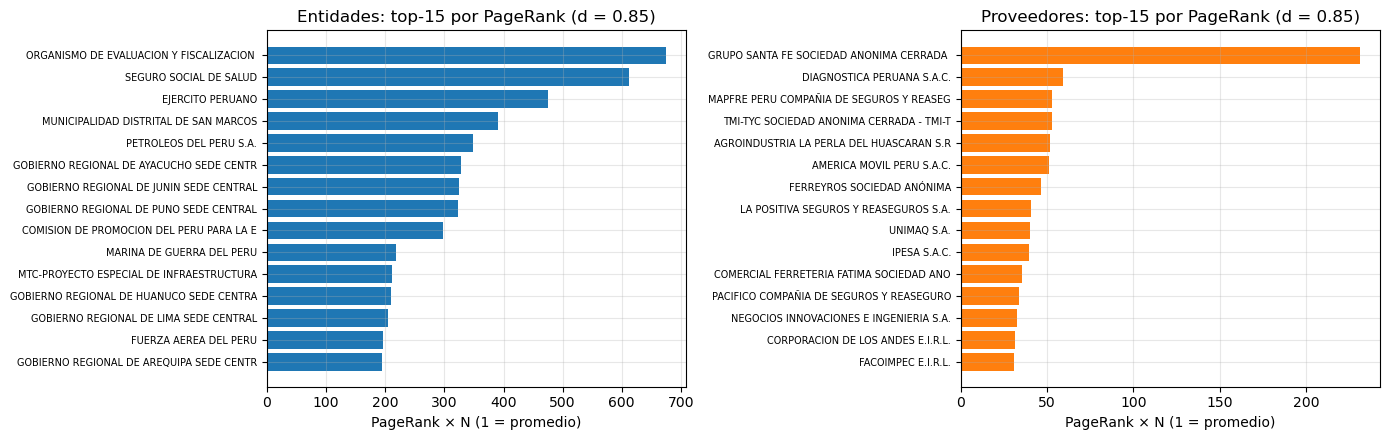

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k_, (t, d) in enumerate((("Entidades", top_ent), ("Proveedores", top_prov))):
    d = d.iloc[::-1]
    ax[k_].barh([str(n)[:40] for n in d.nombre], d.pr * len(v), color="tab:blue" if k_ == 0 else "tab:orange")
    ax[k_].set(xlabel="PageRank × N (1 = promedio)", title=f"{t}: top-15 por PageRank (d = {DAMPING})")
    ax[k_].tick_params(axis="y", labelsize=7)
mostrar_fig("top_pagerank")

- **Entidades de mayor rango:** OEFA, EsSalud, Ejército, Municipalidad de San Marcos, Petroperú y gobiernos regionales

- Compran a cientos de proveedores de forma recurrente

- **Proveedores de mayor rango:** Grupo Santa Fe (275 entidades), Diagnóstica Peruana, Mapfre, TMI-TYC, América Móvil, Ferreyros 

- Todos "grandes multicliente" de KMeans

- **`cuota_billetera`** ordena distinto: premia al proveedor que se lleva gran parte de la compra de varias entidades

---
### **3. Sensibilidad al damping**

- **d → 0:** PageRank → uniforme

- **d → 1:** en un grafo no dirigido conexo

In [14]:
sens, pr_d = [], {}
for d in RANGO_D:
    t0 = time.time(); r, k, err = pagerank_local(M, d=d); seg = time.time() - t0
    pr_d[d] = r
    for t, s_ in (("entidad", slice(0, n_e)), ("proveedor", slice(n_e, None))):
        sens.append({"d": d, "tipo": t, "iteraciones": k, "iter_teoricas": int(np.ceil(np.log(TOL) / np.log(d))),
                     "seg": round(seg, 2), "spearman_vs_085": spearman(r[s_], r_loc[s_]), "top20_vs_085": top_jaccard(r[s_], r_loc[s_]),
                     "spearman_vs_fuerza": spearman(r[s_], v.fuerza.to_numpy()[s_]), "cuota_top1pct": cuota_top(r[s_]), "gini": gini(r[s_])})
sens = pd.DataFrame(sens)
sens.pivot(index="d", columns="tipo", values=["spearman_vs_085", "top20_vs_085", "spearman_vs_fuerza", "cuota_top1pct"]).round(3)

spearman_vs_085           top20_vs_085           spearman_vs_fuerza  \
tipo         entidad proveedor      entidad proveedor            entidad   
d                                                                          
0.50           0.995     0.987        0.905     0.905              0.952   
0.65           0.998     0.993        0.905     1.000              0.958   
0.75           0.999     0.997        1.000     1.000              0.963   
0.85           1.000     1.000        1.000     1.000              0.970   
0.90           0.999     0.998        0.818     0.905              0.974   
0.95           0.997     0.990        0.818     0.818              0.981   
0.99           0.985     0.977        0.739     0.538              0.990   

               cuota_top1pct            
tipo proveedor       entidad proveedor  
d                                       
0.50     0.654         0.169     0.054  
0.65     0.666         0.172     0.083  
0.75     0.679         0.174     0.107  
0.85     0.699         0.177     0.137  
0.90     0.714         0.180     0.155  
0.95     0.734         0.187     0.177  
0.99     0.744         0.200     0.206

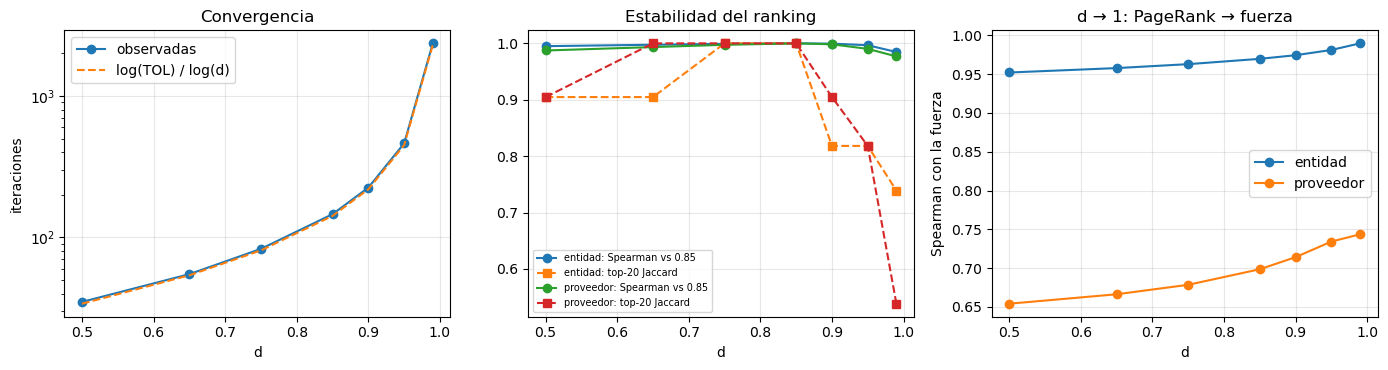

In [15]:
s = sens[sens.tipo == "proveedor"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(s.d, s.iteraciones, "o-", label="observadas"); ax[0].plot(s.d, s.iter_teoricas, "--", label="log(TOL) / log(d)")
ax[0].set(xlabel="d", ylabel="iteraciones", yscale="log", title="Convergencia"); ax[0].legend()
for t, g_ in sens.groupby("tipo"):
    ax[1].plot(g_.d, g_.spearman_vs_085, "o-", label=f"{t}: Spearman vs 0.85")
    ax[1].plot(g_.d, g_.top20_vs_085, "s--", label=f"{t}: top-20 Jaccard")
    ax[2].plot(g_.d, g_.spearman_vs_fuerza, "o-", label=t)
ax[1].set(xlabel="d", title="Estabilidad del ranking"); ax[1].legend(fontsize=7)
ax[2].set(xlabel="d", ylabel="Spearman con la fuerza", title="d → 1: PageRank → fuerza"); ax[2].legend()
mostrar_fig("sensibilidad_damping")

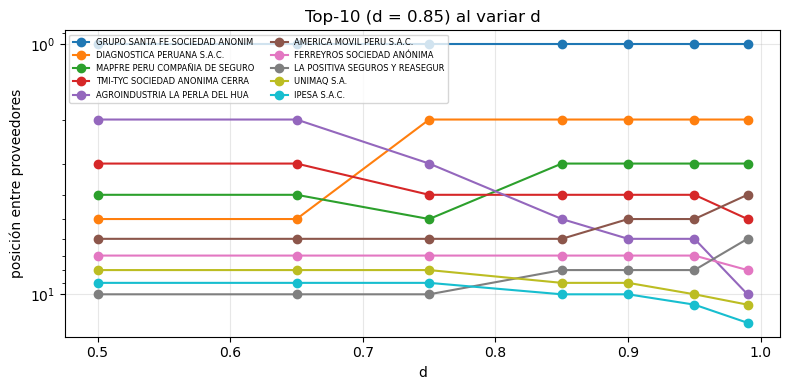

In [16]:
top10 = np.argsort(-r_loc[n_e:])[:10]
rangos = {d: pd.Series(-r[n_e:]).rank(method="min").to_numpy() for d, r in pr_d.items()}
fig, ax = plt.subplots(figsize=(8, 4))
for i in top10:
    ax.plot(RANGO_D, [rangos[d][i] for d in RANGO_D], "o-", label=str(v.nombre[n_e + i])[:30])
ax.set(xlabel="d", ylabel="posición entre proveedores", yscale="log", title="Top-10 (d = 0.85) al variar d")
ax.invert_yaxis(); ax.legend(fontsize=6, ncol=2)
mostrar_fig("rango_top10_vs_damping")

- **Convergencia:** las iteraciones siguen la cota log(TOL)/log(d): 146 con d = 0.85 y 2,354 con d = 0.99

- **Estabilidad:** entre 0.75 y 0.90 el ranking casi no cambia; 0.85 está en la zona estable

- Con d = 0.5 el teletransporte aplana el puntaje: la cuota del top 1% de proveedores baja de 13.7% a 5.4%

- Con d = 0.99 el ranking se acerca a la fuerza (Spearman 0.99 en entidades, 0.74 en proveedores)

- El top-20 de proveedores cambia a la mitad (Jaccard 0.54)

---
### **4. Escritura de resultados**

In [17]:
pd.DataFrame({"idx": v.idx, "pr": r_loc, "pr_spark": r_spark,
              **{f"pr_d{int(round(d * 100))}": r for d, r in pr_d.items()}}).to_parquet(datos_dir / "pagerank.parquet", index=False)
config["damping"] = DAMPING
guardar_config(config)

web = []
for d, r in pr_d.items():
    t = v[["tipo", "clave", "nombre", "region"]].assign(d=d, pr=r)
    t["posicion"] = t.groupby("tipo").pr.rank(ascending=False, method="min").astype(int)
    web.append(t[t.posicion <= N_WEB])
web = pd.concat(web, ignore_index=True)

escritos = guardar_tablas({"tiempos": tiempos, "top_entidades": top_ent, "top_proveedores": top_prov,
                           "sensibilidad_damping": sens, "pagerank_damping_web": web})

Escrito en 04_PageRank/temp/b_pagerank/: tiempos, top_entidades, top_proveedores, sensibilidad_damping, pagerank_damping_web


`pagerank_damping_web`: top-200 por tipo para cada d

#### a. Verificación

In [18]:
verificar_salidas(escritos)
assert np.abs(r_spark - r_loc).max() < 1e-5, "Spark y local no coinciden"
assert all(abs(r.sum() - 1) < 1e-9 for r in pr_d.values()), "algún PageRank no suma 1"
print("Spark = local | todos los PageRank suman 1")

OK: 5 tablas (parquet + json) | 5 figuras: rango_top10_vs_damping, sensibilidad_damping, spark_vs_local, tiempos, top_pagerank
Spark = local | todos los PageRank suman 1


---
### **5. Cerrar sesión**

In [19]:
spark.stop()